# 14 - Non-homogeneous equations

**MATH 331 - Differential Equations.** Lecture plan: Sessions 13 and 14 (Unit 6: undetermined coefficients; variation of parameters).

**References**
* J. Lebl, *Notes on Diffy Qs*: **Section 2.5, Nonhomogeneous equations**: Theorem 2.5.1, the
  opening example, the note on initial conditions, undetermined coefficients (also when the guess
  must change), variation of parameters on $y'' + y = \tan x$. Exercises 2.5.1, 2.5.2, 2.5.3,
  2.5.7, 2.5.8, 2.5.9, 2.5.11, 2.5.13, 2.5.16 (numbers of the list at the end of the chapter).
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012): **Section
  3.4** (Examples 1, 5 and 9; Theorem 8) and **Section 5.6** (Theorem 1, Remark 2, Example 4).
  Their examples are rewritten here with the letter $x$.
* Related notebooks: 05 (the Wronskian), 06 (characteristic roots), 11 (integrating factor), 07
  (the other half of Session 14). Videos R08 (2 x 2 linear systems), R07 (determinants).

**What you will learn**
1. Why **one** particular solution is enough: $y = y_c + y_p$.
2. Undetermined coefficients: how to guess $y_p$ for a variety of right-hand sides.
3. When the guess must be multiplied by $x$, and where that $x$ comes from.
4. Variation of parameters: a formula for $y_p$ that needs no guess.

## 1. Theory in brief

**Structure** (Lebl, Theorem 2.5.1). For a linear equation $L y = f(x)$, here
$a\,y'' + b\,y' + c\,y = f(x)$:

$$ \boxed{\;y = y_c + y_p\;} $$

$y_c$: the general solution of the homogeneous equation $L y = 0$ (notebook 06), with its two
constants. $y_p$: **any one** solution of $L y = f$. Initial conditions are imposed on the sum.

**Undetermined coefficients** (constant coefficients; $f$ made of polynomials, exponentials,
sines and cosines). Guess a function of the same family, with unknown coefficients:

| Right-hand side $f(x)$ | Guess for $y_p$ |
|---|---|
| polynomial of degree $n$ | polynomial of degree $n$, all coefficients unknown |
| $e^{\alpha x}$ | $A\,e^{\alpha x}$ |
| $\cos\beta x$ or $\sin\beta x$ | $A\cos\beta x + B\sin\beta x$ (always both) |
| polynomial of degree $n$ times $e^{\alpha x}\cos\beta x$ or $e^{\alpha x}\sin\beta x$ | $e^{\alpha x}\big(P(x)\cos\beta x + Q(x)\sin\beta x\big)$, $P$ and $Q$ polynomials of degree $n$, all coefficients unknown |
| a sum | one term at a time, then add |

**If a term of the guess solves the homogeneous equation, multiply the whole guess by $x$**; if
one still does, by $x^2$. Precisely: the right-hand side $e^{\alpha x}\cos\beta x$ (times a
polynomial) has the number $\alpha + i\beta$; the
power of $x$ is the number of times this number is a root of the characteristic equation
(0, 1 or 2).

**Variation of parameters** (any continuous $f$; equation $y'' + p(x)\,y' + q(x)\,y = f(x)$ with
known $y_c = C_1y_1 + C_2y_2$). Look for $y_p = u_1(x)\,y_1 + u_2(x)\,y_2$ with

$$ u_1'y_1 + u_2'y_2 = 0, \qquad u_1'y_1' + u_2'y_2' = f, \qquad\text{so}\qquad
   u_1' = -\frac{y_2\,f}{W}, \quad u_2' = \frac{y_1\,f}{W}, $$

where $W = y_1y_2' - y_1'y_2$ is the Wronskian (notebook 05).

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: forced_response, root_multiplicity, constant_coefficient_solution, check, check_solution).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. One particular solution is enough

*Lebl, the opening example of Section 2.5.* $\;y'' + 5y' + 6y = 2x + 1$, $\;y(0) = 0$,
$y'(0) = \tfrac13$. By hand, in three steps.

1. **A particular solution.** The right-hand side is a polynomial of degree 1: try
   $y_p = Ax + B$. Then $y_p' = A$, $y_p'' = 0$ and
   $\;0 + 5A + 6(Ax + B) = 6A\,x + (5A + 6B)$. This must be $2x + 1$: $\;6A = 2$, $5A + 6B = 1$,
   so $A = \tfrac13$, $B = -\tfrac19$.
2. **The homogeneous equation.** $r^2 + 5r + 6 = (r + 2)(r + 3)$: $\;y_c = C_1e^{-2x} + C_2e^{-3x}$.
3. **Initial conditions, on the sum** $y = y_c + y_p$: $\;C_1 + C_2 - \tfrac19 = 0$,
   $\;-2C_1 - 3C_2 + \tfrac13 = \tfrac13$. So $C_1 = \tfrac13$, $C_2 = -\tfrac29$:

$$ y = \tfrac13e^{-2x} - \tfrac29e^{-3x} + \tfrac{3x - 1}{9} . $$

**Why is one $y_p$ enough?** If $y_p$ and $\tilde y_p$ both solve $L y = f$, their difference
solves $L y = 0$: it is already inside $y_c$. Two people with different particular solutions
write the same general solution.

**A common mistake** (Lebl's note): finding $C_1$, $C_2$ from $y_c$ alone and adding $y_p$
afterwards. The code below does it on purpose, to see the damage.

In SymPy the three steps are the same. The function `find_coefficients` does step 1 for any
guess; it is used in the whole notebook.

In [2]:
x = sp.symbols("x")
A, B = sp.symbols("A B")
C_1, C_2 = sp.symbols("C_1 C_2")


def left_side(y, a, b, c):
    # a y'' + b y' + c y for a formula y
    return a * sp.diff(y, x, 2) + b * sp.diff(y, x) + c * y


def find_coefficients(guess, coefficients, right_side, unknowns):
    # the values of the unknowns for which the guess solves the equation, or None if there are none
    difference = sp.expand(left_side(guess, *coefficients) - right_side)
    try:
        found = sp.solve_undetermined_coeffs(difference, unknowns, x)
    except Exception:
        return None
    if not found or sp.simplify(difference.subs(found)) != 0:
        return None
    return found


OPENING = (1, 5, 6)                         # Lebl: y'' + 5y' + 6y = 2x + 1
OPENING_RIGHT = 2 * x + 1
OPENING_START = (0, sp.Rational(1, 3))      # y(0), y'(0)

values = find_coefficients(A * x + B, OPENING, OPENING_RIGHT, [A, B])
y_p = (A * x + B).subs(values)
y_c = C_1 * sp.exp(-2 * x) + C_2 * sp.exp(-3 * x)


def fit(formula):
    # the constants for which the formula has the initial data of the example
    return sp.solve([formula.subs(x, 0) - OPENING_START[0], sp.diff(formula, x).subs(x, 0) - OPENING_START[1]], [C_1, C_2])


solution = (y_c + y_p).subs(fit(y_c + y_p))
mistake = y_c.subs(fit(y_c)) + y_p          # constants from y_c alone: the common mistake
print("A, B:", values, "   y_p =", y_p)
print("solution:", solution)
print("the mistake gives y(0) =", mistake.subs(x, 0), "and y'(0) =", sp.diff(mistake, x).subs(x, 0), "instead of 0 and 1/3")

lebl = sp.exp(-2 * x) / 3 - 2 * sp.exp(-3 * x) / 9 + (3 * x - 1) / 9
assert sp.simplify(solution - lebl) == 0 and sp.simplify(left_side(solution, *OPENING) - OPENING_RIGHT) == 0
assert mistake.subs(x, 0) != OPENING_START[0]

A, B: {A: 1/3, B: -1/9}    y_p = x/3 - 1/9
solution: x/3 - 1/9 + exp(-2*x)/3 - 2*exp(-3*x)/9
the mistake gives y(0) = -1/9 and y'(0) = 2/3 instead of 0 and 1/3


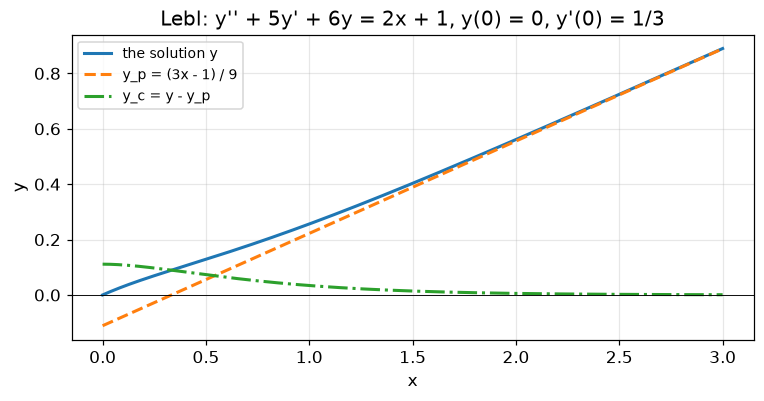

In [3]:
FIGURE_SIZE = (8.0, 3.6)
N_POINTS = 400
OPENING_END = 3.0

points = np.linspace(0.0, OPENING_END, N_POINTS)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(points, sp.lambdify(x, solution)(points), "-", linewidth=2, label="the solution y")
ax.plot(points, sp.lambdify(x, y_p)(points), "--", linewidth=2, label="y_p = (3x - 1) / 9")
ax.plot(points, sp.lambdify(x, solution - y_p)(points), "-.", linewidth=2, label="y_c = y - y_p")
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Lebl: y'' + 5y' + 6y = 2x + 1, y(0) = 0, y'(0) = 1/3")
ax.legend(loc="upper left")
plt.show()

numerical = ol.forced_response(points, *OPENING, lambda s: 2 * s + 1, 0.0, 1 / 3)
assert np.allclose(numerical, sp.lambdify(x, solution)(points))       # the library agrees

*The plot shows* the solution (solid), which starts at 0 and after about $x = 2$ cannot be
told from the dashed straight line $y_p = (3x - 1)/9$, rising from $-0.11$ to $0.89$. The
dash-dot curve is the difference $y_c$: it starts at $0.11$ and dies out. The solution is the
line plus a correction that remembers the initial data for a short while.

## 3. A variety of forcing terms

The right-hand side $f$ is often called the **forcing term**. Three by hand; the code checks
each by substitution.

**An exponential** (*Adkins and Davidson, Section 3.4, Example 1*). $\;y'' - y' - 6y = e^{-x}$.
Try $y_p = Ae^{-x}$: $\;(A + A - 6A)\,e^{-x} = e^{-x}$, so $A = -\tfrac14$.

**A cosine** (*Lebl, Section 2.5*). $\;y'' + 2y' + 2y = \cos 2x$. The derivative of a cosine is a
sine, so the guess needs **both**: $y_p = A\cos 2x + B\sin 2x$. Substituting and collecting,

$$ (-2A + 4B)\cos 2x + (-4A - 2B)\sin 2x = \cos 2x: \qquad -2A + 4B = 1, \quad -4A - 2B = 0 , $$

so $A = -\tfrac1{10}$, $B = \tfrac15$. (Question: the right-hand side has no sine. Does the
solution? Yes: $B \ne 0$.)

**A sum** (*Adkins and Davidson, Section 3.4, Theorem 8 and Example 9*).
$\;y'' - 5y' + 6y = 12 + 4e^{2x}$. One term at a time: for $12$ the guess is a constant, $y_p = 2$;
for $4e^{2x}$ see Section 4. Add the two results: the equation is linear.

exponential: {A: -1/4}
cosine and sine: {A: -1/10, B: 1/5}
cosine alone: None (no value of A works)
amplitude of y_p: 0.224; its maxima come 1.02 after those of cos 2x


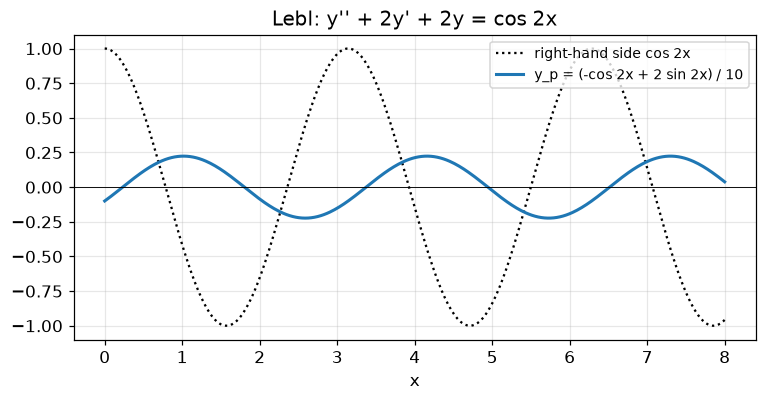

In [4]:
EXPONENTIAL = (1, -1, -6)                   # Adkins-Davidson 3.4, Example 1
COSINE = (1, 2, 2)                          # Lebl
COSINE_END = 8.0

found_exponential = find_coefficients(A * sp.exp(-x), EXPONENTIAL, sp.exp(-x), [A])
found_cosine = find_coefficients(A * sp.cos(2 * x) + B * sp.sin(2 * x), COSINE, sp.cos(2 * x), [A, B])
only_cosine = find_coefficients(A * sp.cos(2 * x), COSINE, sp.cos(2 * x), [A])
print("exponential:", found_exponential)
print("cosine and sine:", found_cosine)
print("cosine alone:", only_cosine, "(no value of A works)")
assert found_exponential == {A: -sp.Rational(1, 4)} and found_cosine == {A: -sp.Rational(1, 10), B: sp.Rational(1, 5)}
assert only_cosine is None

y_cosine = (A * sp.cos(2 * x) + B * sp.sin(2 * x)).subs(found_cosine)
amplitude = sp.sqrt(found_cosine[A] ** 2 + found_cosine[B] ** 2)
delay = sp.atan2(found_cosine[B], found_cosine[A]) / 2
print(f"amplitude of y_p: {float(amplitude):.3f}; its maxima come {float(delay):.2f} after those of cos 2x")

points = np.linspace(0.0, COSINE_END, N_POINTS)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(points, np.cos(2 * points), ":", color="black", label="right-hand side cos 2x")
ax.plot(points, sp.lambdify(x, y_cosine)(points), "-", linewidth=2, label="y_p = (-cos 2x + 2 sin 2x) / 10")
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_xlabel("x")
ax.set_title("Lebl: y'' + 2y' + 2y = cos 2x")
ax.legend(loc="upper right")
plt.show()

*The plot shows* the forcing term $\cos 2x$ (dotted, between $-1$ and $1$) and the particular
solution (solid): a wave of the same period $\pi$, but about 4.5 times smaller (amplitude 0.224)
and late: each of its maxima comes about 1.02 after a maximum of the forcing term. That delay is
what the sine in the guess is for.

## 4. When the guess must change

*Lebl's "hiccup".* $\;y'' - 9y = e^{3x}$. The guess $Ae^{3x}$ gives
$9Ae^{3x} - 9Ae^{3x} = 0$: no $A$ can make this equal to $e^{3x}$. The reason:
$y_c = C_1e^{-3x} + C_2e^{3x}$ already contains the guess.

**The cure: multiply by $x$.** With $y_p = Axe^{3x}$: $\;y_p'' - 9y_p = 6Ae^{3x}$, so $A = \tfrac16$.

*A double root* (Lebl). $\;y'' - 6y' + 9y = e^{3x}$: now $y_c = (C_1 + C_2x)\,e^{3x}$ contains
$xe^{3x}$ too. Multiply once more: $y_p = Ax^2e^{3x}$ gives $A = \tfrac12$. Lebl: multiply the
guess by $x$ "until all duplication is gone. But no more!"

*Adkins and Davidson, Section 3.4, Example 5.* $\;y'' - 5y' + 6y = 4e^{2x}$: the roots are 2 and 3,
so the guess is $Axe^{2x}$, and $A = -4$. With Section 3: $y_p = 2 - 4xe^{2x}$ for their Example 9.

**The rule.** Read the number $\alpha + i\beta$ from the right-hand side (in notebook 06 these
letters were the roots; here they describe $f$) ($e^{3x}$: 3;
$\cos 2x$: $2i$; $e^{-x}\cos x$: $-1 + i$; a polynomial: 0). Multiply the usual guess by $x^s$,
where $s$ is the number of times that number is a root of the characteristic equation.

**Where does the $x$ come from?** Take $y'' - 9y = e^{cx}$ with $c$ near 3 but not 3 (here $c$ is
a number in the exponent, as in Lebl's Exercise 2.5.8; it is not the coefficient of $y$). The
plain guess works: $y_p = \dfrac{e^{cx}}{c^2 - 9}$, whose coefficient explodes as $c \to 3$. But subtracting a solution of the
homogeneous equation gives another particular solution,

$$ y_p = \frac{e^{cx} - e^{3x}}{c^2 - 9} \;\longrightarrow\; \frac{x\,e^{3x}}{6} \quad (c \to 3), $$

because $\dfrac{e^{cx} - e^{3x}}{c - 3}$ is a difference quotient, whose limit is the derivative
$\dfrac{\partial}{\partial c}e^{cx} = x\,e^{cx}$ at $c = 3$, and the other factor $\dfrac{1}{c + 3}$
tends to $\tfrac16$. It is the same story as the repeated root of
notebook 06, Section 3.

Before moving the slider: what is the coefficient $\dfrac{1}{c^2 - 9}$ of the plain guess at $c = 3.1$?
At $c = 3.01$? Will the curve on the screen jump when $c$ passes through 3?

plain guess: None
times x:     {A: 1/6}
double root, times x:   None
double root, times x^2: {A: 1/2}
Adkins-Davidson, Example 5: {A: -4}
powers of x from the rule: 1 2 1 and for cos 2x in Section 3: 0


limit as c tends to 3: x*exp(3*x)/6


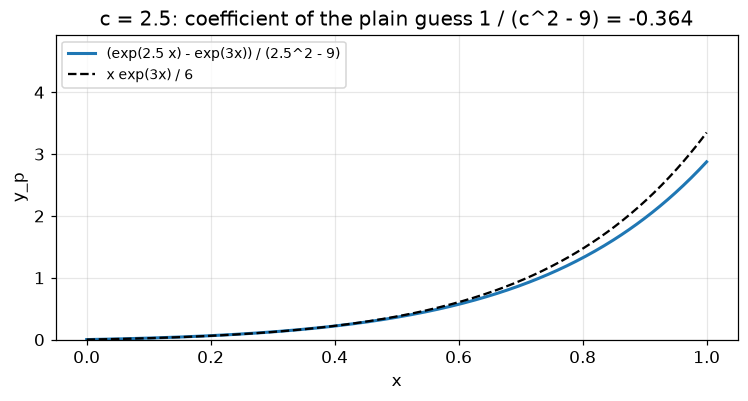

In [5]:
HICCUP = (1, 0, -9)                         # Lebl: y'' - 9y = exp(3x)
DOUBLE = (1, -6, 9)                         # Lebl: y'' - 6y' + 9y = exp(3x)
ADKINS_5 = (1, -5, 6)                       # Adkins-Davidson 3.4, Example 5: right-hand side 4 exp(2x)
ROOT = 3.0                                  # the root of r^2 - 9 that the right-hand side meets
FAMILY_END = 1.0
DEFAULT_C = 2.5
c_symbol = sp.symbols("c")

print("plain guess:", find_coefficients(A * sp.exp(3 * x), HICCUP, sp.exp(3 * x), [A]))
print("times x:    ", find_coefficients(A * x * sp.exp(3 * x), HICCUP, sp.exp(3 * x), [A]))
print("double root, times x:  ", find_coefficients(A * x * sp.exp(3 * x), DOUBLE, sp.exp(3 * x), [A]))
print("double root, times x^2:", find_coefficients(A * x ** 2 * sp.exp(3 * x), DOUBLE, sp.exp(3 * x), [A]))
print("Adkins-Davidson, Example 5:", find_coefficients(A * x * sp.exp(2 * x), ADKINS_5, 4 * sp.exp(2 * x), [A]))
print("powers of x from the rule:", ol.root_multiplicity(*HICCUP, 3), ol.root_multiplicity(*DOUBLE, 3),
      ol.root_multiplicity(*ADKINS_5, 2), "and for cos 2x in Section 3:", ol.root_multiplicity(*COSINE, 0, 2))

limit = sp.limit((sp.exp(c_symbol * x) - sp.exp(3 * x)) / (c_symbol ** 2 - 9), c_symbol, 3)
print("limit as c tends to 3:", limit)
assert sp.simplify(limit - x * sp.exp(3 * x) / 6) == 0
assert find_coefficients(A * x * sp.exp(2 * x), ADKINS_5, 4 * sp.exp(2 * x), [A]) == {A: -4}


def family(points, c):
    # the particular solution (exp(c x) - exp(3 x)) / (c^2 - 9) of y'' - 9y = exp(c x), and its limit at c = 3
    if np.isclose(c, ROOT):
        return points * np.exp(ROOT * points) / (2 * ROOT)
    return (np.exp(c * points) - np.exp(ROOT * points)) / (c * c - ROOT * ROOT)


def plot_family(c=DEFAULT_C):
    # the particular solution for this c (solid) and the limit x exp(3x) / 6 (dashed)
    points = np.linspace(0.0, FAMILY_END, N_POINTS)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(points, family(points, c), "-", linewidth=2, label=f"(exp({c:g} x) - exp(3x)) / ({c:g}^2 - 9)")
    ax.plot(points, family(points, ROOT), "--", color="black", label="x exp(3x) / 6")
    ax.set_ylim(0.0, family(FAMILY_END, C_RANGE[1]))
    ax.set_xlabel("x")
    ax.set_ylabel("y_p")
    if np.isclose(c, ROOT):
        ax.set_title("c = 3: the plain guess fails; the curve is the limit")
    else:
        ax.set_title(f"c = {c:g}: coefficient of the plain guess 1 / (c^2 - 9) = {1 / (c * c - ROOT * ROOT):.3g}")
    ax.legend(loc="upper left")
    plt.show()


C_RANGE = (2.0, 4.0, 0.05)                  # minimum, maximum, step
plot_family()

In [6]:
interact(plot_family,
         c=FloatSlider(value=DEFAULT_C, min=C_RANGE[0], max=C_RANGE[1], step=C_RANGE[2], description="c",
                       continuous_update=False));

interactive(children=(FloatSlider(value=2.5, continuous_update=False, description='c', max=4.0, min=2.0, step=...

*The static plot shows*, for $c = 2.5$, the particular solution
$(e^{2.5x} - e^{3x})/(2.5^2 - 9)$ (solid) on $0 \le x \le 1$: it starts at 0 and rises to 2.87;
the dashed curve is the limit $xe^{3x}/6$, a little above it, reaching 3.35. The title gives the
coefficient of the plain guess, $-0.364$.

(Answers: 1.64 at $c = 3.1$ and 16.6 at $c = 3.01$: the plain guess explodes. The curve does not
jump: it passes smoothly through the dashed one at $c = 3$.)

## 5. What stays and what fades

Back to $y'' + 2y' + 2y = \cos 2x$. Its characteristic roots are $-1 \pm i$, so
$y_c = e^{-x}(C_1\cos x + C_2\sin x)$ dies out, whatever the constants. All the solutions, from
any initial data, end on the **same** curve: $y_p$.

* $y_c$ is the **transient**: it carries the initial data and fades;
* $y_p$ is the **steady** part: it depends on the forcing term only.

(These words come back in notebook 15. When $y_c$ does not die out, as for the undamped spring
of notebook 07, Section 3, there is no such division.)

Before running: the transient is multiplied by $e^{-x}$. After which $x$ is it below 1 % of its
first size?

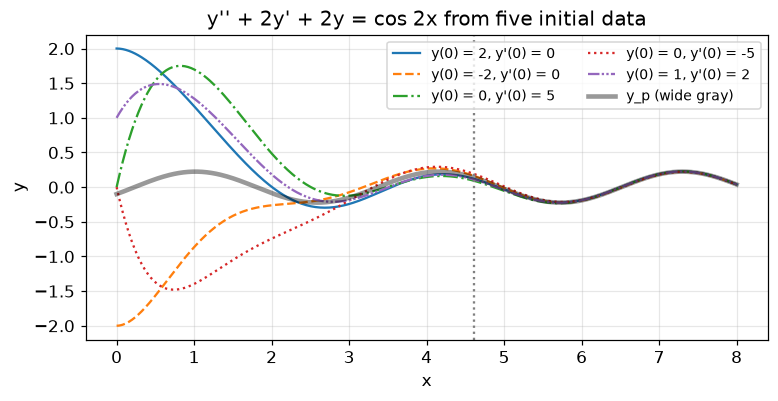

exp(-x) is below 1 % after x = ln 100 = 4.61


In [7]:
STARTS = ((2.0, 0.0), (-2.0, 0.0), (0.0, 5.0), (0.0, -5.0), (1.0, 2.0))      # five pairs y(0), y'(0)
STYLES = ("-", "--", "-.", ":", (0, (5, 1, 1, 1, 1, 1)))       # the last one: dash, dot, dot
TRANSIENT_END = 8.0
ONE_PERCENT = 0.01


def forced_cosine(points, y0, v0):
    # the solution of y'' + 2y' + 2y = cos 2x with y(0) = y0, y'(0) = v0: y_p plus a homogeneous solution
    steady = sp.lambdify(x, y_cosine)(points)
    slope_0 = float(sp.diff(y_cosine, x).subs(x, 0))
    return steady + ol.constant_coefficient_solution(points, *COSINE, y0 - float(y_cosine.subs(x, 0)), v0 - slope_0)


points = np.linspace(0.0, TRANSIENT_END, N_POINTS)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
for (y0, v0), style in zip(STARTS, STYLES):
    ax.plot(points, forced_cosine(points, y0, v0), linestyle=style, linewidth=1.5, label=f"y(0) = {y0:g}, y'(0) = {v0:g}")
ax.plot(points, sp.lambdify(x, y_cosine)(points), "-", color="black", linewidth=3, alpha=0.4, label="y_p (wide gray)")
ax.axvline(np.log(1 / ONE_PERCENT), linestyle=":", color="gray")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("y'' + 2y' + 2y = cos 2x from five initial data")
ax.legend(loc="upper right", ncol=2)
plt.show()

check_points = np.linspace(0.0, TRANSIENT_END, 9)
assert np.allclose(forced_cosine(check_points, *STARTS[2]),
                   ol.forced_response(check_points, *COSINE, lambda s: np.cos(2 * s), *STARTS[2]))
print(f"exp(-x) is below 1 % after x = ln 100 = {np.log(1 / ONE_PERCENT):.2f}")

*The plot shows* five solutions with different initial data (different line styles). They start
far apart, between $-2$ and $2$, some rising and some falling, and all of them join the wide gray
wave $y_p$ of amplitude 0.224; soon after the dotted vertical line at $x = 4.6$ they cannot
be told apart. (Answer: after $x = \ln 100 \approx 4.6$.)

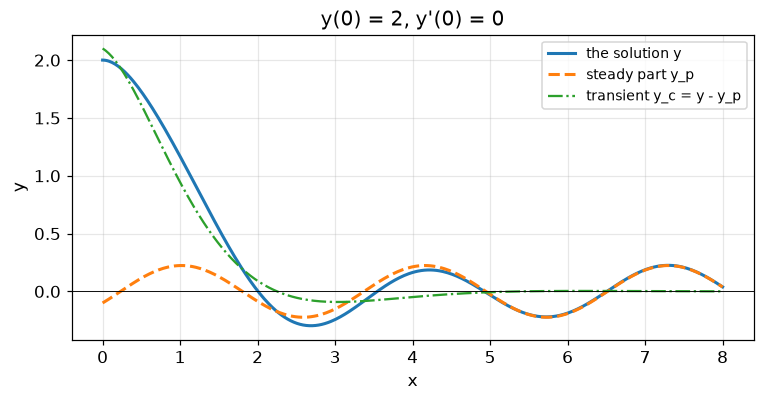

In [8]:
START_DEFAULTS = {"y0": 2.0, "v0": 0.0}
Y0_RANGE = (-2.0, 2.0, 0.1)                 # minimum, maximum, step
V0_RANGE = (-5.0, 5.0, 0.1)


def plot_transient(y0=START_DEFAULTS["y0"], v0=START_DEFAULTS["v0"]):
    # the solution with these initial data (solid), the steady part y_p (dashed), the transient (dash-dot)
    points = np.linspace(0.0, TRANSIENT_END, N_POINTS)
    steady = sp.lambdify(x, y_cosine)(points)
    total = forced_cosine(points, y0, v0)
    fig, ax = plt.subplots(figsize=FIGURE_SIZE)
    ax.plot(points, total, "-", linewidth=2, label="the solution y")
    ax.plot(points, steady, "--", linewidth=2, label="steady part y_p")
    ax.plot(points, total - steady, "-.", linewidth=1.5, label="transient y_c = y - y_p")
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"y(0) = {y0:g}, y'(0) = {v0:g}")
    ax.legend(loc="upper right")
    plt.show()


plot_transient()

**Sliders.** Before moving them: are there initial data for which there is **no** transient at
all?

In [9]:
interact(plot_transient,
         y0=FloatSlider(value=START_DEFAULTS["y0"], min=Y0_RANGE[0], max=Y0_RANGE[1], step=Y0_RANGE[2], description="y(0)",
                        continuous_update=False),
         v0=FloatSlider(value=START_DEFAULTS["v0"], min=V0_RANGE[0], max=V0_RANGE[1], step=V0_RANGE[2], description="y'(0)",
                        continuous_update=False));

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='y(0)', max=2.0, min=-2.0), ...

*The static plot shows*, for $y(0) = 2$, $y'(0) = 0$: the solution (solid) falls from 2 and from
about $x = 5$ follows the dashed wave $y_p$; the transient (dash-dot) starts at 2.1, dips a little
below zero (to $-0.09$ near $x = 3$) and is gone.

(Answer: yes, exactly one pair: the values of $y_p$ and $y_p'$ at 0, that is $y(0) = -0.1$ and
$y'(0) = 0.4$. Then the solution is $y_p$ itself.)

## 6. Variation of parameters

Undetermined coefficients needs a right-hand side whose derivatives stay in a finite family. For
$y'' + y = \tan x$ there is nothing to guess: every derivative of $\tan x$ is a new function
(Lebl). **Variation of parameters** needs no guess: it needs $y_c$.

**The derivation**, for $y'' + p(x)\,y' + q(x)\,y = f(x)$ with $y_c = C_1y_1 + C_2y_2$.

1. Replace the constants by functions: $\;y_p = u_1y_1 + u_2y_2$. Two unknown functions and one
   equation: we may impose **one more condition**, of our choice.
2. $y_p' = (u_1'y_1 + u_2'y_2) + (u_1y_1' + u_2y_2')$. Choose the condition
   $\;u_1'y_1 + u_2'y_2 = 0$: then $y_p' = u_1y_1' + u_2y_2'$, with no derivative of $u$.
3. $y_p'' = (u_1'y_1' + u_2'y_2') + (u_1y_1'' + u_2y_2'')$.
4. Substitute in the equation. The terms with $u_1$ are $u_1(y_1'' + py_1' + qy_1) = 0$, because
   $y_1$ solves the homogeneous equation; the same for $u_2$. What is left is
   $\;u_1'y_1' + u_2'y_2' = f$.
5. Two linear equations for $u_1'$, $u_2'$. Their determinant is the Wronskian $W$, which is
   never zero because $y_1$, $y_2$ are independent solutions (notebook 05). By Cramer's rule (video R08):

$$ u_1' = -\frac{y_2\,f}{W}, \qquad u_2' = \frac{y_1\,f}{W}; \qquad
   y_p = -y_1\!\int\!\frac{y_2\,f}{W}\,dx + y_2\!\int\!\frac{y_1\,f}{W}\,dx . $$

This is Theorem 1 of Adkins and Davidson, Section 5.6. They add (Remark 2) that the formula is
not to be memorised: remember the two conditions of steps 2 and 4. The coefficient of $y''$ must
be 1 before reading $f$.

*Lebl's example.* $\;y'' + y = \tan x$, on $-\tfrac\pi2 < x < \tfrac\pi2$. $y_1 = \cos x$,
$y_2 = \sin x$, $W = 1$:

$$ u_1' = -\sin x\tan x = \cos x - \frac{1}{\cos x}, \qquad u_2' = \cos x\tan x = \sin x , $$

$$ u_1 = \sin x + \tfrac12\ln\frac{1 - \sin x}{1 + \sin x}, \qquad u_2 = -\cos x , \qquad
   y_p = u_1\cos x + u_2\sin x = \tfrac12\cos x\,\ln\frac{1 - \sin x}{1 + \sin x} . $$

For a first-order equation the same idea (replace the constant of $y_c$ by a function) gives the
integrating-factor formula of notebook 11.

W = 1   u_1' = -sin(x)*tan(x)   u_2' = sin(x)


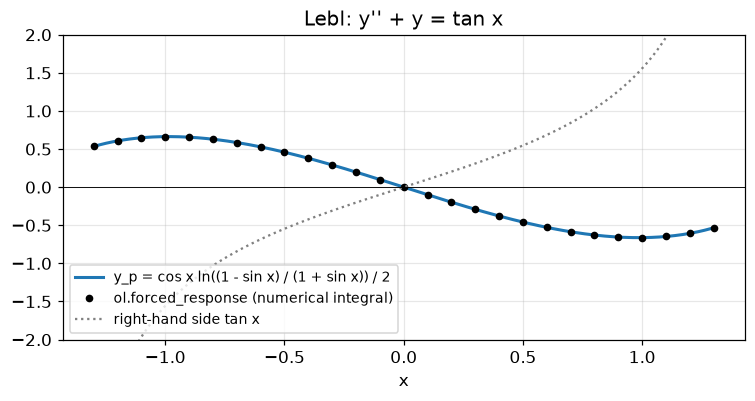

y_p'(0) = -1; y_p(1.3) = -0.533


In [10]:
TAN_END = 1.3                               # the picture stays inside (-pi/2, pi/2)
N_DOTS = 27

y_1, y_2, forcing = sp.cos(x), sp.sin(x), sp.tan(x)
wronskian = sp.simplify(y_1 * sp.diff(y_2, x) - sp.diff(y_1, x) * y_2)
du_1, du_2 = sp.simplify(-y_2 * forcing / wronskian), sp.simplify(y_1 * forcing / wronskian)
u_1 = sp.sin(x) + sp.log((1 - sp.sin(x)) / (1 + sp.sin(x))) / 2          # the integrals found by hand
u_2 = -sp.cos(x)
by_hand = sp.cos(x) * sp.log((1 - sp.sin(x)) / (1 + sp.sin(x))) / 2
print("W =", wronskian, "  u_1' =", du_1, "  u_2' =", du_2)
assert sp.simplify(sp.diff(u_1, x) - du_1) == 0 and sp.simplify(sp.diff(u_2, x) - du_2) == 0    # an integral is checked by differentiating
assert sp.simplify(u_1 * y_1 + u_2 * y_2 - by_hand) == 0

points = np.linspace(-TAN_END, TAN_END, N_POINTS)
dots = np.linspace(-TAN_END, TAN_END, N_DOTS)
hand_values = sp.lambdify(x, by_hand)(points)
assert np.allclose(sp.lambdify(x, sp.diff(by_hand, x, 2) + by_hand - forcing)(points), 0.0, atol=1e-9)   # it solves the equation
slope_0 = float(sp.diff(by_hand, x).subs(x, 0))
numerical = ol.forced_response(dots, 1, 0, 1, np.tan, 0.0, slope_0)                             # same data at x = 0

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(points, hand_values, "-", linewidth=2, label="y_p = cos x ln((1 - sin x) / (1 + sin x)) / 2")
ax.plot(dots, numerical, "o", color="black", markersize=4, label="ol.forced_response (numerical integral)")
ax.plot(points, np.tan(points), ":", color="gray", label="right-hand side tan x")
ax.set_ylim(-2.0, 2.0)
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_xlabel("x")
ax.set_title("Lebl: y'' + y = tan x")
ax.legend(loc="lower left")
plt.show()

assert np.allclose(numerical, sp.lambdify(x, by_hand)(dots), atol=1e-7)
print(f"y_p'(0) = {slope_0:g}; y_p({TAN_END:g}) = {float(by_hand.subs(x, TAN_END)):.3f}")

*The plot shows* the particular solution of $y'' + y = \tan x$ between $-1.3$ and $1.3$ (solid):
it rises to about $0.66$ near $x = -1$, passes through the origin going down, and falls to
about $-0.66$ near $x = 1$. The
black dots, computed by numerical integration with the same data at $x = 0$, lie on it. The
dotted curve is the forcing term $\tan x$, which leaves the picture near $\pm 1.1$.

## 7. Which method? And what if the integrals cannot be done?

| | Undetermined coefficients | Variation of parameters |
|---|---|---|
| equation | constant coefficients | any linear equation whose $y_c$ is known |
| right-hand side | sums of terms "polynomial times exponential times sine or cosine" | any continuous function |
| work | algebra: a small linear system | two integrals |

When both apply, undetermined coefficients is quicker. The two answers may **look different**:
they differ by a solution of the homogeneous equation (Exercise 4).

*A variable coefficient* (Adkins and Davidson, Section 5.6, Example 4): $\;x\,y'' + 2y' + x\,y = 1$,
in Exercise 3. Divide by $x$ first: $f = \dfrac1x$.

*No closed form* (Lebl, Exercise 2.5.7). $\;y'' - 2y' + y = \sin(x^2)$: the integrals of variation
of parameters cannot be written with elementary functions. A computer can still evaluate them:
`ol.forced_response` is variation of parameters for constant coefficients, with the integral
done numerically. It returns the solution with $y(0) = y_0$, $y'(0) = v_0$ (zero if not given).

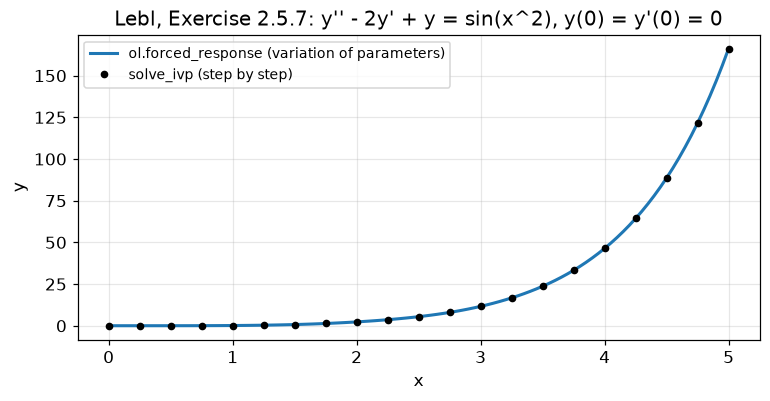

y(5) = 166.23


In [11]:
HARD = (1, -2, 1)                           # Lebl, Exercise 2.5.7: y'' - 2y' + y = sin(x^2)
HARD_END = 5.0
N_HARD = 101
TIGHT = 1e-10


def hard_forcing(s):
    return np.sin(s * s)


points = np.linspace(0.0, HARD_END, N_HARD)
by_formula = ol.forced_response(points, *HARD, hard_forcing)                    # starts from rest
by_steps = solve_ivp(lambda s, state: [state[1], hard_forcing(s) + 2 * state[1] - state[0]], (0.0, HARD_END), [0.0, 0.0],
                     t_eval=points[::5], rtol=TIGHT, atol=TIGHT)

fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.plot(points, by_formula, "-", linewidth=2, label="ol.forced_response (variation of parameters)")
ax.plot(by_steps.t, by_steps.y[0], "o", color="black", markersize=4, label="solve_ivp (step by step)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Lebl, Exercise 2.5.7: y'' - 2y' + y = sin(x^2), y(0) = y'(0) = 0")
ax.legend(loc="upper left")
plt.show()

assert np.allclose(by_formula[::5], by_steps.y[0], rtol=1e-7, atol=1e-7)
print(f"y({HARD_END:g}) = {by_formula[-1]:.2f}")

*The plot shows* the solution of $y'' - 2y' + y = \sin(x^2)$ that starts from rest, on
$0 \le x \le 5$: small until $x = 1$ (where it is 0.12), then growing faster and faster (the homogeneous
solutions are $e^x$ and $xe^x$), to about 166 at $x = 5$. The black dots, from a step-by-step
numerical method, lie on the curve.

## 8. Exercises

Final answers are at the end; try first.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

By which power of $x$ must the usual guess be multiplied: 0, 1 or 2?

* (a) $y'' - y' - 6y = e^{2x}$ *(Lebl, Exercise 2.5.1)*
* (b) $y'' - 4y' + 4y = e^{2x}$ *(Lebl, Exercise 2.5.2)*
* (c) $y'' + 9y = \cos 3x + \sin 3x$ *(Lebl, Exercise 2.5.3)*
* (d) $y'' - 5y' + 6y = 4e^{2x}$ *(Adkins and Davidson, Section 3.4, Example 5)*
* (e) $y'' + 2y' + 2y = e^{-x}\cos x$
* (f) $y'' + 2y' + 2y = \cos x$

And: can undetermined coefficients find a particular solution of $y'' + y = \tan x$? (`True` or
`False`.)

In [12]:
my_powers = None                # a list of six numbers, for example [0, 0, 0, 0, 0, 0]
my_guessing_works = None        # True or False
# ---- your answers go above this line; the lines below check them (nothing to change) ----

EQUATIONS = (((1, -1, -6), (2, 0)), ((1, -4, 4), (2, 0)), ((1, 0, 9), (0, 3)),
             (ADKINS_5, (2, 0)), (COSINE, (-1, 1)), (COSINE, (0, 1)))            # coefficients; alpha and beta
ol.check("Exercise 1, powers", my_powers, [ol.root_multiplicity(*equation, *number) for equation, number in EQUATIONS])
ol.check("Exercise 1, tan x", my_guessing_works, False);

Exercise 1, powers: no answer yet (replace None with your value)
Exercise 1, tan x: no answer yet (replace None with your value)


### Exercise 2 - By hand, then check

Find **a** particular solution of (a), (b), (c), and **the** solution of (d). Type them as SymPy
formulas in `x` (for example `x * sp.exp(3 * x) / 6`).

* (a) $y'' - y' - 6y = e^{2x}$ *(Lebl, Exercise 2.5.1)*
* (b) $y'' - 4y' + 4y = e^{2x}$ *(Lebl, Exercise 2.5.2)*
* (c) $y'' - y' + y = 2\sin 3x$ *(Lebl, Exercise 2.5.11)*
* (d) $y'' + 2y' + y = x^2$, $\;y(0) = 1$, $y'(0) = 2$ *(Lebl, Exercise 2.5.13)*

The check substitutes your formula in the equation, so for (a), (b), (c) every correct particular
solution is accepted, however it is written.

In [13]:
my_a = None
my_b = None
my_c = None
my_d = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

INTERVAL = (0.0, 2.0)
ol.check_solution("Exercise 2a", my_a, lambda y: left_side(y, 1, -1, -6) - sp.exp(2 * x), x, INTERVAL)
ol.check_solution("Exercise 2b", my_b, lambda y: left_side(y, 1, -4, 4) - sp.exp(2 * x), x, INTERVAL)
ol.check_solution("Exercise 2c", my_c, lambda y: left_side(y, 1, -1, 1) - 2 * sp.sin(3 * x), x, INTERVAL)
ol.check_solution("Exercise 2d", my_d, lambda y: left_side(y, 1, 2, 1) - x ** 2, x, INTERVAL,
                  conditions=((0, 1), (0, 2, 1)));              # y(0) = 1 and y'(0) = 2

Exercise 2a: no answer yet (replace None with your formula)
Exercise 2b: no answer yet (replace None with your formula)
Exercise 2c: no answer yet (replace None with your formula)
Exercise 2d: no answer yet (replace None with your formula)


### Exercise 3 - Fill in

Complete the function `u_derivatives`: from the two solutions $y_1$, $y_2$ of the homogeneous
equation and the right-hand side $f$ it must return the two formulas $u_1'$ and $u_2'$ of
variation of parameters, separated by a comma. The function `wronskian_of` is given. The next
cell integrates your formulas, builds $y_p = u_1y_1 + u_2y_2$ and substitutes it in three
equations.

In [14]:
def wronskian_of(first, second):
    return sp.simplify(first * sp.diff(second, x) - sp.diff(first, x) * second)


def u_derivatives(y1, y2, f):
    return None                 # replace None with the formula

In [15]:
# name, y1, y2, right-hand side (coefficient of y'' equal to 1), residual of the equation, interval of the check
TRIALS = (("y'' + y = tan x (Lebl)", sp.cos(x), sp.sin(x), sp.tan(x),
           lambda y: left_side(y, 1, 0, 1) - sp.tan(x), (-1.0, 1.0)),
          ("y'' - y = exp(x) (Lebl, Exercise 2.5.9)", sp.exp(x), sp.exp(-x), sp.exp(x),
           lambda y: left_side(y, 1, 0, -1) - sp.exp(x), (0.5, 2.5)),
          ("x y'' + 2y' + x y = 1 (Adkins-Davidson 5.6, Example 4)", sp.sin(x) / x, sp.cos(x) / x, 1 / x,
           lambda y: x * sp.diff(y, x, 2) + 2 * sp.diff(y, x) + x * y - 1, (0.5, 2.5)))

if u_derivatives(sp.cos(x), sp.sin(x), sp.tan(x)) is None:
    print("Exercise 3: complete u_derivatives first")
else:
    passed = 0
    for name, first, second, right_side, residual, interval in TRIALS:
        try:
            du_1, du_2 = u_derivatives(first, second, right_side)
            particular = sp.integrate(sp.simplify(du_1), x) * first + sp.integrate(sp.simplify(du_2), x) * second
        except Exception:
            print("Exercise 3: not yet (return the two formulas, separated by a comma)")
            break
        passed += ol.check_solution(f"Exercise 3, {name}", particular, residual, x, interval)
    else:
        print("Exercise 3: correct" if passed == len(TRIALS) else "Exercise 3: not yet (check the signs, and which solution goes where)")

Exercise 3: complete u_derivatives first


### Exercise 4 - Explore

* *(Lebl, Exercise 2.5.9)* For $y'' - y = e^x$ undetermined coefficients give $\tfrac12xe^x$, and
  variation of parameters (with $y_1 = e^x$, $y_2 = e^{-x}$) gives $\tfrac12xe^x - \tfrac14e^x$. Check
  both with `ol.check_solution`. Are they the same? What is going on?
* *(Lebl, Exercise 2.5.8)* Find a particular solution of $y'' - y = e^{cx}$ for **every** real
  $c$. (Three cases. The slider of Section 4 shows the idea.)
* *(Lebl, Exercise 2.5.16)* Guessing also works for some equations without constant
  coefficients: find a polynomial that solves $y' + x\,y = x^3 + 2x^2 + 5x + 2$.
* Change the right-hand side of Section 7 to one of your own and plot the solution.

In [16]:
# your code here: for example
# ol.check_solution("first", x * sp.exp(x) / 2, lambda y: left_side(y, 1, 0, -1) - sp.exp(x), x, INTERVAL)

## 9. Answers

Final answers only; full solutions are given after the session.

<details>
<summary>Click to open (after trying)</summary>

1. `[0, 2, 1, 1, 1, 0]`. (a) the roots are 3 and $-2$, and the number is 2; (b) 2 is a double
   root; (c) $3i$ is a root; (d) 2 is a root; (e) $-1 + i$ is a root; (f) the number is $i$, the
   roots are $-1 \pm i$: no change. `False`: the derivatives of $\tan x$ never repeat.
2. (a) $-\tfrac14e^{2x}$. (b) $\tfrac12x^2e^{2x}$. (c) $\dfrac{-16\sin 3x + 6\cos 3x}{73}$.
   (d) $x^2 - 4x + 6 + e^{-x}(x - 5)$.
3. `return -y2 * f / wronskian_of(y1, y2), y1 * f / wronskian_of(y1, y2)`
4. Both are right: they differ by $-\tfrac14e^x$, a solution of the homogeneous equation. For
   $y'' - y = e^{cx}$: $\;\dfrac{e^{cx}}{c^2 - 1}$ if $c \ne \pm 1$; $\tfrac12xe^x$ if $c = 1$;
   $-\tfrac12xe^{-x}$ if $c = -1$. The polynomial is $x^2 + 2x + 3$.

</details>

**Where to go next:** notebook 07 (free vibrations, the second half of Session 14), then notebook 15
(forced vibrations and resonance, Session 15), where the right-hand side is a force and the factor $x$ of
Section 4 becomes an oscillation that grows without bound.